<a href="https://colab.research.google.com/github/6374157880/UPI-Transaction-spending-bahaviour-analysis/blob/main/EDA%20ASSIGNMENT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# PROGRAM 1: IMPORT LIBRARIES
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from IPython.display import display

sns.set_theme(style="whitegrid")
print("UPI Transaction & Spending Behaviour Analysis")
print("Libraries imported successfully!")

UPI Transaction & Spending Behaviour Analysis
Libraries imported successfully!


In [5]:
# PROGRAM 2: LOAD DATASET
import os

local_file_path = "/content/upi_transaction_spending_behaviour_500_records.csv"

# Safely load the dataset without calling the blocking files.upload() if the file is already present
if os.path.exists(local_file_path):
    df = pd.read_csv(local_file_path)
    print("Dataset loaded directly from local path:", local_file_path)

    # Map matching columns from the uploaded dataset to standard names uniquely
    column_mapping = {
        "transaction_id": "Transaction_ID",
        "transaction_datetime": "Datetime",
        "transaction_date": "Date",
        "transaction_time": "Time",
        "amount": "Amount",
        "transaction_type": "Transaction_Type",
        "merchant_category": "Merchant_Category",
        "payment_mode": "Payment_Mode",
        "status": "Status",
        "cashback": "Cashback"
    }

    # Rename columns that exist in mapping
    rename_dict = {col: column_mapping[col] for col in df.columns if col in column_mapping}
    df = df.rename(columns=rename_dict)
else:
    # Fallback to interactive upload if the file is missing
    print("Local file not found, opening upload dialog...")
    uploaded = files.upload()
    if uploaded:
        filename = next(iter(uploaded))
        df = pd.read_csv(filename)
        print("Dataset loaded:", filename)

        column_mapping = {
            "transaction_id": "Transaction_ID",
            "transaction_datetime": "Datetime",
            "transaction_date": "Date",
            "transaction_time": "Time",
            "amount": "Amount",
            "transaction_type": "Transaction_Type",
            "merchant_category": "Merchant_Category",
            "payment_mode": "Payment_Mode",
            "status": "Status",
            "cashback": "Cashback"
        }
        rename_dict = {col: column_mapping[col] for col in df.columns if col in column_mapping}
        df = df.rename(columns=rename_dict)
    else:
        np.random.seed(42)
        n = 500
        dates = pd.date_range("2025-01-01", "2025-12-31", periods=n)
        df = pd.DataFrame({
            "Transaction_ID": [f"UPI{i:04d}" for i in range(1, n + 1)],
            "Date": dates,
            "Time": [f"{np.random.randint(0,24):02d}:{np.random.randint(0,60):02d}" for _ in range(n)],
            "Amount": np.round(np.random.lognormal(5.0, 0.8, n), 2),
            "Transaction_Type": np.random.choice(["Send Money", "Shopping", "Bill Payment", "Recharge", "Food"], n),
            "Merchant_Category": np.random.choice(["Grocery", "Food", "Shopping", "Bills", "Travel", "Entertainment"], n),
            "Payment_Mode": np.random.choice(["Google Pay", "PhonePe", "Paytm", "BHIM"], n),
            "Status": np.random.choice(["Success", "Failed", "Pending"], n, p=[0.94, 0.04, 0.02]),
            "Cashback": np.round(np.random.choice([0, 5, 10, 20, 30], n), 2)
        })
        print("Sample UPI dataset created successfully!")

# Safely convert to datetime
if "Date" in df.columns:
    df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
else:
    print("Warning: 'Date' column not found. Available columns:", df.columns.tolist())

if "Datetime" in df.columns:
    df["Datetime"] = pd.to_datetime(df["Datetime"], errors="coerce")

print("\nDataset Preview:")
display(df.head(10))
print("\nDataset Shape:", df.shape)
print("\nColumn Names:", df.columns.tolist())

Dataset loaded directly from local path: /content/upi_transaction_spending_behaviour_500_records.csv

Dataset Preview:


,Transaction_ID,user_id,Datetime,Date,day_of_week,transaction_hour,amount_inr,Transaction_Type,Merchant_Category,merchant_type,city,payment_app,device_type,network_type,transaction_status,cashback_inr,is_weekend
0,UPI2501010449,USR056,2025-01-01 08:06:00,2025-01-01,Wednesday,8,2299.28,P2M,Fuel,EV Charging,Chennai,Google Pay,Android,Wi-Fi,Success,22.99,False
1,UPI2501010279,USR071,2025-01-01 08:40:00,2025-01-01,Wednesday,8,762.02,P2P,Person-to-Person,Individual,Chennai,Other,Android,5G,Success,0.00,False
2,UPI2501010110,USR100,2025-01-01 10:55:00,2025-01-01,Wednesday,10,1167.75,P2M,Utilities,Electricity,Salem,Other,Android,4G,Pending,0.00,False
3,UPI2501010098,USR065,2025-01-01 20:13:00,2025-01-01,Wednesday,20,574.31,P2M,Groceries,Supermarket,Salem,PhonePe,Android,5G,Success,5.74,False
4,UPI2501020199,USR048,2025-01-02 03:35:00,2025-01-02,Thursday,3,4860.37,P2M,Education,College,Chennai,Other,Android,5G,Failed,0.00,False
5,UPI2501020311,USR026,2025-01-02 07:40:00,2025-01-02,Thursday,7,2424.20,P2M,Healthcare,Clinic,Chennai,Google Pay,Android,4G,Success,12.12,False
6,UPI2501020293,USR061,2025-01-02 16:00:00,2025-01-02,Thursday,16,1624.24,P2M,Food & Dining,Cafe,Chennai,Other,Android,5G,Success,0.00,False
7,UPI2501020038,USR072,2025-01-02 18:50:00,2025-01-02,Thursday,18,818.23,P2M,Transport,Ride Hailing,Trichy,Google Pay,Android,5G,Failed,0.00,False
8,UPI2501040088,USR049,2025-01-04 03:10:00,2025-01-04,Saturday,3,463.47,P2M,Food & Dining,Food Delivery,Chennai,Google Pay,Android,5G,Failed,0.00,True
9,UPI2501040119,USR022,2025-01-04 10:43:00,2025-01-04,Saturday,10,704.36,P2M,Groceries,Online Grocery,Madurai,PhonePe,iOS,4G,Success,0.00,True



Dataset Shape: (500, 17)

Column Names: ['Transaction_ID', 'user_id', 'Datetime', 'Date', 'day_of_week', 'transaction_hour', 'amount_inr', 'Transaction_Type', 'Merchant_Category', 'merchant_type', 'city', 'payment_app', 'device_type', 'network_type', 'transaction_status', 'cashback_inr', 'is_weekend']


In [6]:
# PROGRAM 3: DATASET OVERVIEW
print("Dataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe(include="all"))

print("\nTransaction Status Count:")
for status_col in ["transaction_status", "Status"]:
    if status_col in df.columns:
        print(f"\nCounts for {status_col}:")
        display(df[status_col].value_counts())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Transaction_ID      500 non-null    object        
 1   user_id             500 non-null    object        
 2   Datetime            500 non-null    datetime64[ns]
 3   Date                500 non-null    datetime64[ns]
 4   day_of_week         500 non-null    object        
 5   transaction_hour    500 non-null    int64         
 6   amount_inr          500 non-null    float64       
 7   Transaction_Type    500 non-null    object        
 8   Merchant_Category   500 non-null    object        
 9   merchant_type       500 non-null    object        
 10  city                500 non-null    object        
 11  payment_app         500 non-null    object        
 12  device_type         500 non-null    object        
 13  network_type        500 non-n

,Transaction_ID,user_id,Datetime,Date,day_of_week,transaction_hour,amount_inr,Transaction_Type,Merchant_Category,merchant_type,city,payment_app,device_type,network_type,transaction_status,cashback_inr,is_weekend
count,500,500,500,500,500,500.000000,500.000000,500,500,500,500,500,500,500,500,500.000000,500
unique,500,99,NaN,NaN,7,NaN,NaN,2,11,30,8,5,2,3,3,NaN,2
top,UPI2501010449,USR047,NaN,NaN,Thursday,NaN,NaN,P2M,Food & Dining,Individual,Chennai,PhonePe,Android,4G,Success,NaN,False
freq,1,11,NaN,NaN,84,NaN,NaN,430,79,70,146,181,440,251,466,NaN,358
mean,NaN,NaN,2025-07-02 13:53:01.320000,2025-07-02 01:23:31.200000256,NaN,11.996000,1440.786360,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.800840,NaN
min,NaN,NaN,2025-01-01 08:06:00,2025-01-01 00:00:00,NaN,0.000000,28.580000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN
25%,NaN,NaN,2025-03-27 08:00:00,2025-03-27 00:00:00,NaN,6.000000,411.427500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN
50%,NaN,NaN,2025-06-25 07:36:00,2025-06-24 12:00:00,NaN,12.000000,761.575000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN
75%,NaN,NaN,2025-10-06 17:59:30,2025-10-06 06:00:00,NaN,18.000000,1800.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.272500,NaN
max,NaN,NaN,2025-12-31 17:02:00,2025-12-31 00:00:00,NaN,23.000000,20468.540000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,106.240000,NaN



Transaction Status Count:

Counts for transaction_status:


,count
transaction_status,
Success,466
Failed,27
Pending,7


In [7]:
# PROGRAM 4: DATA CLEANING
print("Missing Values Before Cleaning:")
display(df.isnull().sum())
print("Duplicate Rows:", df.duplicated().sum())

df = df.drop_duplicates().copy()

# Safely resolve target metric columns
amount_col = "amount_inr" if "amount_inr" in df.columns else ("Amount" if "Amount" in df.columns else None)
status_col = "transaction_status" if "transaction_status" in df.columns else ("Status" if "Status" in df.columns else None)
payment_col = "payment_app" if "payment_app" in df.columns else ("Payment_Mode" if "Payment_Mode" in df.columns else None)

if amount_col:
    df[amount_col] = pd.to_numeric(df[amount_col], errors="coerce")
    df[amount_col] = df[amount_col].fillna(df[amount_col].median())

if "Date" in df.columns:
    df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Fill categorical column NaNs
categoricals = [col for col in ["Transaction_Type", "Merchant_Category", payment_col, status_col] if col]
for col in categoricals:
    if col in df.columns:
        df[col] = df[col].fillna("Unknown")

print("\nMissing Values After Cleaning:")
display(df.isnull().sum())
print("\nCleaned Dataset Preview:")
display(df.head())

Missing Values Before Cleaning:


,0
Transaction_ID,0
user_id,0
Datetime,0
Date,0
day_of_week,0
transaction_hour,0
amount_inr,0
Transaction_Type,0
Merchant_Category,0
merchant_type,0


Duplicate Rows: 0

Missing Values After Cleaning:


,0
Transaction_ID,0
user_id,0
Datetime,0
Date,0
day_of_week,0
transaction_hour,0
amount_inr,0
Transaction_Type,0
Merchant_Category,0
merchant_type,0



Cleaned Dataset Preview:


,Transaction_ID,user_id,Datetime,Date,day_of_week,transaction_hour,amount_inr,Transaction_Type,Merchant_Category,merchant_type,city,payment_app,device_type,network_type,transaction_status,cashback_inr,is_weekend
0,UPI2501010449,USR056,2025-01-01 08:06:00,2025-01-01,Wednesday,8,2299.28,P2M,Fuel,EV Charging,Chennai,Google Pay,Android,Wi-Fi,Success,22.99,False
1,UPI2501010279,USR071,2025-01-01 08:40:00,2025-01-01,Wednesday,8,762.02,P2P,Person-to-Person,Individual,Chennai,Other,Android,5G,Success,0.00,False
2,UPI2501010110,USR100,2025-01-01 10:55:00,2025-01-01,Wednesday,10,1167.75,P2M,Utilities,Electricity,Salem,Other,Android,4G,Pending,0.00,False
3,UPI2501010098,USR065,2025-01-01 20:13:00,2025-01-01,Wednesday,20,574.31,P2M,Groceries,Supermarket,Salem,PhonePe,Android,5G,Success,5.74,False
4,UPI2501020199,USR048,2025-01-02 03:35:00,2025-01-02,Thursday,3,4860.37,P2M,Education,College,Chennai,Other,Android,5G,Failed,0.00,False


In [8]:
# PROGRAM 5: SPENDING ANALYSIS
amount_col = "amount_inr" if "amount_inr" in df.columns else "Amount"

print("Total Spending: ₹", round(df[amount_col].sum(), 2))
print("Average Transaction: ₹", round(df[amount_col].mean(), 2))
print("Highest Transaction: ₹", round(df[amount_col].max(), 2))
print("Lowest Transaction: ₹", round(df[amount_col].min(), 2))
print("Number of Transactions:", len(df))

print("\nSpending by Transaction Type:")
display(df.groupby("Transaction_Type")[amount_col].agg(["count", "sum", "mean"]).sort_values("sum", ascending=False))

print("\nSpending by Merchant Category:")
display(df.groupby("Merchant_Category")[amount_col].sum().sort_values(ascending=False))

Total Spending: ₹ 720393.18
Average Transaction: ₹ 1440.79
Highest Transaction: ₹ 20468.54
Lowest Transaction: ₹ 28.58
Number of Transactions: 500

Spending by Transaction Type:


,count,sum,mean
Transaction_Type,,,
P2M,430,615911.30,1432.351860
P2P,70,104481.88,1492.598286



Spending by Merchant Category:


,amount_inr
Merchant_Category,
Shopping,140320.88
Travel,111701.57
Person-to-Person,104481.88
Education,86124.39
Groceries,68826.67
Utilities,47774.35
Food & Dining,41145.43
Healthcare,39741.10
Fuel,39443.47


Transactions by payment_app:


,count
payment_app,
PhonePe,181
Google Pay,166
Paytm,71
BHIM,44
Other,38



Average Spending by payment_app:


,amount_inr
payment_app,
Google Pay,1627.341867
Other,1544.048947
PhonePe,1432.333425
Paytm,1210.102254
BHIM,1054.794545



Transaction Status count (transaction_status):


,count
transaction_status,
Success,466
Failed,27
Pending,7


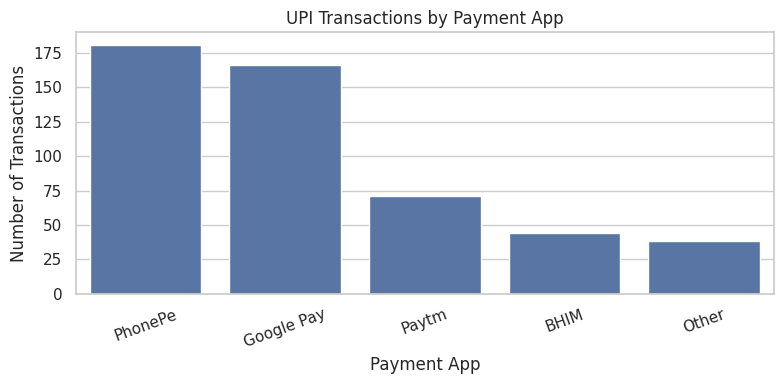

In [9]:
# PROGRAM 6: PAYMENT MODE ANALYSIS
amount_col = "amount_inr" if "amount_inr" in df.columns else "Amount"
payment_col = "payment_app" if "payment_app" in df.columns else "Payment_Mode"
status_col = "transaction_status" if "transaction_status" in df.columns else "Status"

print(f"Transactions by {payment_col}:")
display(df[payment_col].value_counts())

print(f"\nAverage Spending by {payment_col}:")
display(df.groupby(payment_col)[amount_col].mean().sort_values(ascending=False))

print(f"\nTransaction Status count ({status_col}):")
display(df[status_col].value_counts())

plt.figure(figsize=(8, 4))
sns.countplot(data=df, x=payment_col, order=df[payment_col].value_counts().index)
plt.title("UPI Transactions by Payment App")
plt.xlabel("Payment App")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

Monthly Spending:


,amount_inr
Month,
2025-01,53027.55
2025-02,56523.05
2025-03,59628.18
2025-04,48381.33
2025-05,68895.97
2025-06,53852.44
2025-07,55291.78
2025-08,56687.66
2025-09,85669.49


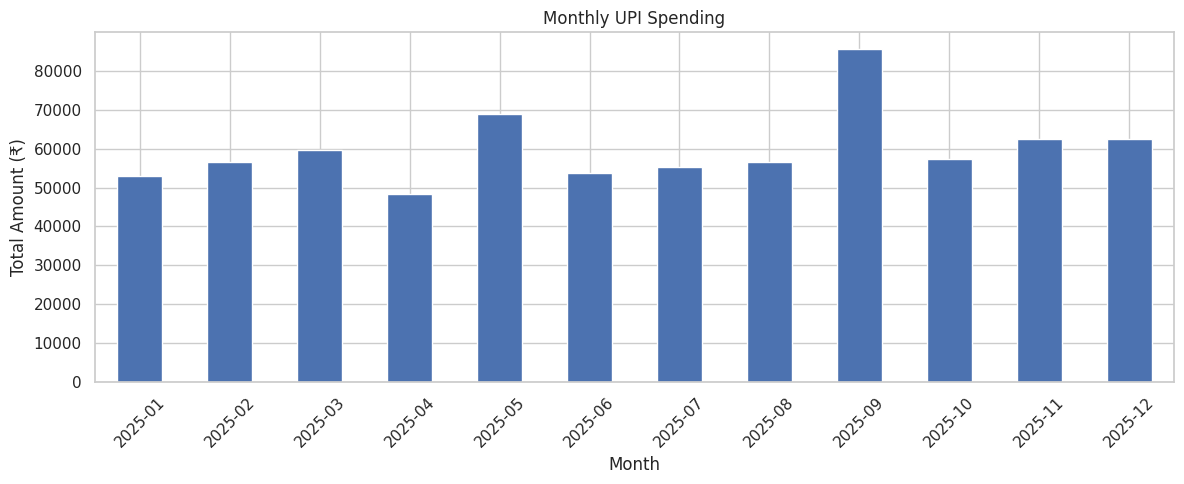


Transactions by Hour (from dataset):


,count
transaction_hour,
0,24
1,17
2,19
3,17
4,19
5,15
6,18
7,20
8,25


In [10]:
# PROGRAM 7: MONTHLY SPENDING ANALYSIS
amount_col = "amount_inr" if "amount_inr" in df.columns else "Amount"

df["Month"] = df["Date"].dt.to_period("M").astype(str)
monthly_spending = df.groupby("Month")[amount_col].sum()

print("Monthly Spending:")
display(monthly_spending)

plt.figure(figsize=(12, 5))
monthly_spending.plot(kind="bar")
plt.title("Monthly UPI Spending")
plt.xlabel("Month")
plt.ylabel("Total Amount (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Transaction activity by hour
if "transaction_hour" in df.columns:
    print("\nTransactions by Hour (from dataset):")
    display(df["transaction_hour"].value_counts().sort_index())
elif "Time" in df.columns:
    df["Hour"] = pd.to_datetime(df["Time"], format="%H:%M", errors="coerce").dt.hour
    print("\nTransactions by Hour (computed):")
    display(df["Hour"].value_counts().sort_index())

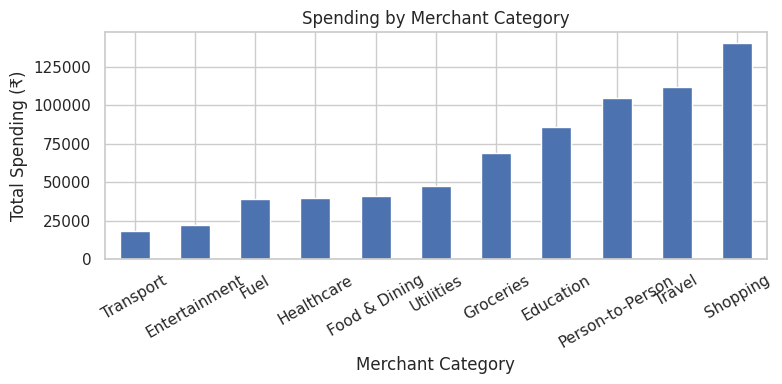

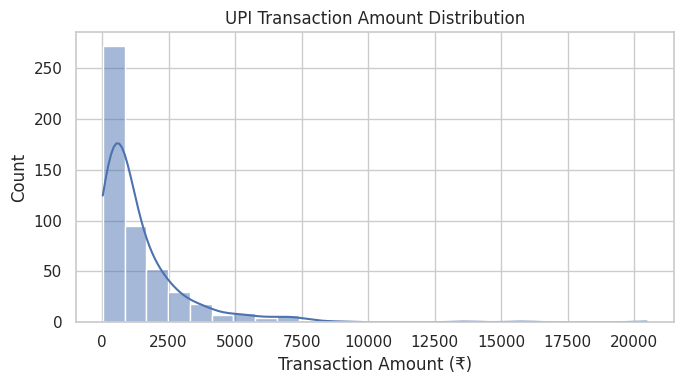

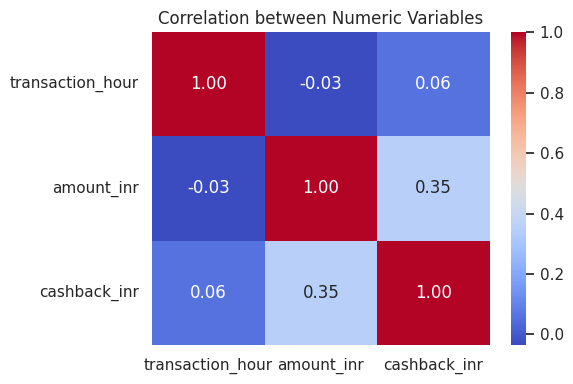


FINAL ANALYSIS
Total UPI Spending: ₹ 720393.18
Average Transaction: ₹ 1440.79
Most Used Payment App: PhonePe
Highest Spending Category: Shopping
UPI transaction analysis completed successfully!


In [11]:
# PROGRAM 8: VISUALIZATION AND CORRELATION
amount_col = "amount_inr" if "amount_inr" in df.columns else "Amount"
payment_col = "payment_app" if "payment_app" in df.columns else "Payment_Mode"

plt.figure(figsize=(8, 4))
df.groupby("Merchant_Category")[amount_col].sum().sort_values().plot(kind="bar")
plt.title("Spending by Merchant Category")
plt.xlabel("Merchant Category")
plt.ylabel("Total Spending (₹)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
sns.histplot(df[amount_col], bins=25, kde=True)
plt.title("UPI Transaction Amount Distribution")
plt.xlabel("Transaction Amount (₹)")
plt.tight_layout()
plt.show()

numeric_df = df.select_dtypes(include=np.number)
if len(numeric_df.columns) > 1:
    plt.figure(figsize=(6, 4))
    sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
    plt.title("Correlation between Numeric Variables")
    plt.tight_layout()
    plt.show()

print("\nFINAL ANALYSIS")
print("Total UPI Spending: ₹", round(df[amount_col].sum(), 2))
print("Average Transaction: ₹", round(df[amount_col].mean(), 2))
print("Most Used Payment App:", df[payment_col].mode()[0])
print("Highest Spending Category:", df.groupby("Merchant_Category")[amount_col].sum().idxmax())
print("UPI transaction analysis completed successfully!")